# Ordenación topológica

En un grafo dirigido acíclico (DAG), ordena los nodos de modo que cada arista $u \to v$ tenga $u$ antes que $v$. Sirve para planificar tareas con dependencias. El algoritmo de Kahn coloca repetidamente los nodos sin dependencias pendientes (grado de entrada 0); si no consigue colocarlos todos, hay un ciclo. Cuesta $O(V + E)$.

## 1. Algoritmo de Kahn

Ordenar las asignaturas de una carrera respetando sus prerrequisitos (`a → b` significa que `a` debe cursarse antes que `b`), o devolver `None` si hay un ciclo.

In [1]:
from collections import deque

def kahn(grafo):
    grado = {n: 0 for n in grafo}
    for vecinos in grafo.values():
        for v in vecinos:
            grado[v] += 1
    cola = deque(n for n in grafo if grado[n] == 0)
    orden = []
    while cola:
        n = cola.popleft()
        orden.append(n)
        for v in grafo[n]:
            grado[v] -= 1
            if grado[v] == 0:
                cola.append(v)
    return orden if len(orden) == len(grafo) else None

plan = {
    "Programación I": ["Programación II", "Estructuras de datos"],
    "Matemáticas": ["Algoritmia"],
    "Programación II": ["Algoritmia"],
    "Estructuras de datos": ["Algoritmia"],
    "Algoritmia": ["Compiladores"],
    "Compiladores": [],
}
print(kahn(plan))
print(kahn({"a": ["b"], "b": ["c"], "c": ["a"]}))

['Programación I', 'Matemáticas', 'Programación II', 'Estructuras de datos', 'Algoritmia', 'Compiladores']
None


## 2. Orden topológico con DFS

Obtener un orden topológico con DFS: un nodo se añade cuando han terminado todos sus descendientes, y al final se invierte la lista. Comprobar que se respetan todas las aristas.

In [2]:
def topologico_dfs(grafo):
    visitados, orden = set(), []
    def visita(n):
        visitados.add(n)
        for v in grafo[n]:
            if v not in visitados:
                visita(v)
        orden.append(n)
    for n in grafo:
        if n not in visitados:
            visita(n)
    return orden[::-1]

orden = topologico_dfs(plan)
posicion = {n: i for i, n in enumerate(orden)}
assert all(posicion[u] < posicion[v] for u in plan for v in plan[u])
print(orden)

['Matemáticas', 'Programación I', 'Estructuras de datos', 'Programación II', 'Algoritmia', 'Compiladores']


## 3. Detectar un ciclo y mostrarlo

Kahn solo dice que hay un ciclo. Con un DFS de tres colores (blanco: sin visitar, gris: en la pila de llamadas, negro: terminado), una arista hacia un nodo gris cierra un ciclo, que se reconstruye con la pila. Comprobar en grafos aleatorios pequeños que hay ciclo exactamente cuando Kahn falla y cuando ninguna permutación de los nodos es un orden topológico, y que, si no lo hay, Kahn y DFS dan órdenes válidos.

In [3]:
import random
from itertools import permutations

def busca_ciclo(grafo):
    color = {n: "blanco" for n in grafo}
    pila = []

    def visita(n):
        color[n] = "gris"
        pila.append(n)
        for v in grafo[n]:
            if color[v] == "gris":
                return pila[pila.index(v):] + [v]
            if color[v] == "blanco":
                ciclo = visita(v)
                if ciclo:
                    return ciclo
        color[n] = "negro"
        pila.pop()
        return None

    for n in grafo:
        if color[n] == "blanco":
            ciclo = visita(n)
            if ciclo:
                return ciclo
    return None

def es_topologico(grafo, orden):
    posicion = {n: i for i, n in enumerate(orden)}
    return all(posicion[u] < posicion[v] for u in grafo for v in grafo[u])

con_ciclo = dict(plan, Compiladores=["Programación II"])
print(kahn(con_ciclo))
print(" → ".join(busca_ciclo(con_ciclo)))
print(busca_ciclo(plan))

def grafo_aleatorio(n, p):
    return {u: [v for v in range(n) if v != u and random.random() < p] for u in range(n)}

random.seed(5)
ciclicos = 0
for _ in range(500):
    g = grafo_aleatorio(random.randint(1, 6), 0.25)
    ciclo = busca_ciclo(g)
    hay_orden = any(es_topologico(g, p) for p in permutations(g))
    assert (ciclo is None) == (kahn(g) is not None) == hay_orden
    if ciclo:
        ciclicos += 1
        assert ciclo[0] == ciclo[-1] and all(b in g[a] for a, b in zip(ciclo, ciclo[1:]))
    else:
        assert es_topologico(g, kahn(g)) and es_topologico(g, topologico_dfs(g))
print(ciclicos, "de 500 grafos tienen ciclo")

None
Programación II → Algoritmia → Compiladores → Programación II
None
175 de 500 grafos tienen ciclo


## 4. Planificar cuatrimestres

Con Kahn por niveles, en cada cuatrimestre se cursan todas las asignaturas cuyos prerrequisitos ya están aprobados, y el número de cuatrimestres es el de asignaturas de la cadena de prerrequisitos más larga. Repetirlo con un máximo de 3 asignaturas por cuatrimestre, dando prioridad a las que empiezan una cadena más larga. Comprobar que cada prerrequisito queda en un cuatrimestre anterior y dibujar los dos planes con `matplotlib`.

Sin límite
  1.º: Programación I, Cálculo, Álgebra
  2.º: Programación II, Arquitectura, Estadística, Métodos numéricos
  3.º: Estructuras de datos, Bases de datos, Gráficos
  4.º: Algoritmia, Sistemas operativos, Ingeniería del software
  5.º: Aprendizaje automático, Compiladores, Redes
Máximo 3 por cuatrimestre
  1.º: Programación I, Cálculo, Álgebra
  2.º: Programación II, Arquitectura, Estadística
  3.º: Estructuras de datos, Métodos numéricos, Bases de datos
  4.º: Algoritmia, Sistemas operativos, Gráficos
  5.º: Ingeniería del software, Aprendizaje automático, Compiladores
  6.º: Redes


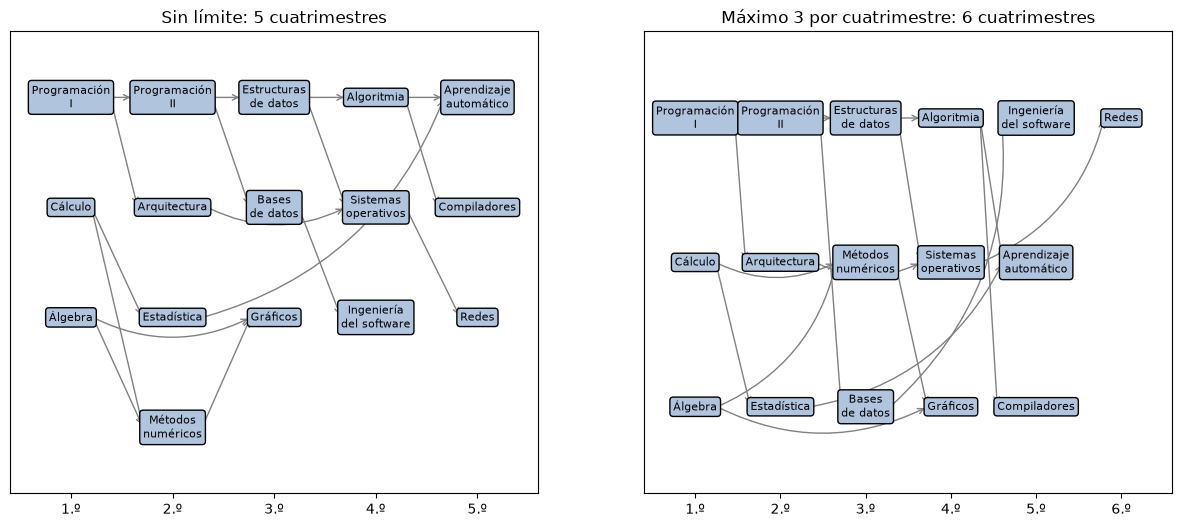

In [4]:
import matplotlib.pyplot as plt

carrera = {
    "Cálculo": ["Estadística", "Métodos numéricos"],
    "Álgebra": ["Métodos numéricos", "Gráficos"],
    "Programación I": ["Programación II", "Arquitectura"],
    "Programación II": ["Estructuras de datos", "Bases de datos"],
    "Arquitectura": ["Sistemas operativos"],
    "Estructuras de datos": ["Algoritmia", "Sistemas operativos"],
    "Estadística": ["Aprendizaje automático"],
    "Métodos numéricos": ["Gráficos"],
    "Bases de datos": ["Ingeniería del software"],
    "Algoritmia": ["Aprendizaje automático", "Compiladores"],
    "Sistemas operativos": ["Redes"],
    "Gráficos": [],
    "Aprendizaje automático": [],
    "Compiladores": [],
    "Ingeniería del software": [],
    "Redes": [],
}

def grados_entrada(grafo):
    grado = {n: 0 for n in grafo}
    for vecinos in grafo.values():
        for v in vecinos:
            grado[v] += 1
    return grado

def cadena(grafo):
    # asignaturas de la cadena más larga que empieza en cada una
    largo = {}
    for n in reversed(kahn(grafo)):
        largo[n] = 1 + max((largo[v] for v in grafo[n]), default=0)
    return largo

def planifica(grafo, maximo=None):
    maximo = maximo or len(grafo)
    grado, largo = grados_entrada(grafo), cadena(grafo)
    disponibles = [n for n in grafo if grado[n] == 0]
    cuatrimestres = []
    while disponibles:
        disponibles.sort(key=lambda n: -largo[n])
        actual, disponibles = disponibles[:maximo], disponibles[maximo:]
        cuatrimestres.append(actual)
        for n in actual:
            for v in grafo[n]:
                grado[v] -= 1
                if grado[v] == 0:
                    disponibles.append(v)
    return cuatrimestres

def comprueba(grafo, cuatrimestres):
    en = {n: i for i, c in enumerate(cuatrimestres) for n in c}
    assert len(en) == len(grafo) and all(en[u] < en[v] for u in grafo for v in grafo[u])

libre, limitado = planifica(carrera), planifica(carrera, 3)
comprueba(carrera, libre)
comprueba(carrera, limitado)
assert len(libre) == max(cadena(carrera).values())
for titulo, plan_c in (("Sin límite", libre), ("Máximo 3 por cuatrimestre", limitado)):
    print(titulo)
    for i, asignaturas in enumerate(plan_c, start=1):
        print(f"  {i}.º: {', '.join(asignaturas)}")

fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
for eje, (titulo, plan_c) in zip(ejes, (("Sin límite", libre), ("Máximo 3 por cuatrimestre", limitado))):
    cajas = {n: eje.text(i, -j, n.replace(" ", "\n", 1), ha="center", va="center", fontsize=8, zorder=3,
                         bbox=dict(boxstyle="round", facecolor="lightsteelblue"))
             for i, c in enumerate(plan_c) for j, n in enumerate(c)}
    columna = {n: i for i, c in enumerate(plan_c) for n in c}
    # del borde derecho de la caja origen al izquierdo de la destino; curvas si saltan cuatrimestres
    for u in carrera:
        for v in carrera[u]:
            curva = 0.25 if columna[v] - columna[u] > 1 else 0
            eje.annotate("", xy=(0, 0.5), xycoords=cajas[v], xytext=(1, 0.5), textcoords=cajas[u], zorder=1,
                         arrowprops=dict(arrowstyle="->", color="gray", connectionstyle=f"arc3,rad={curva}"))
    eje.set_xticks(range(len(plan_c)), [f"{i + 1}.º" for i in range(len(plan_c))])
    eje.set_xlim(-0.6, len(plan_c) - 0.4)
    eje.set_ylim(-max(map(len, plan_c)) + 0.4, 0.6)
    eje.set_yticks([])
    eje.set_title(f"{titulo}: {len(plan_c)} cuatrimestres")
plt.show()